Training Dataset Shape: (10000, 785)
Testing Dataset Shape: (10000, 785)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8638 - loss: 0.4939 - val_accuracy: 0.9650 - val_loss: 0.1346
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9704 - loss: 0.1000 - val_accuracy: 0.9750 - val_loss: 0.0910
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9798 - loss: 0.0641 - val_accuracy: 0.9720 - val_loss: 0.0906
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9850 - loss: 0.0449 - val_accuracy: 0.9780 - val_loss: 0.0736
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9891 - loss: 0.0316 - val_accuracy: 0.9820 - val_loss: 0.0567
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9931 - loss: 0.0226

Test Loss: 0.0226
Test Accuracy: 99.31 %


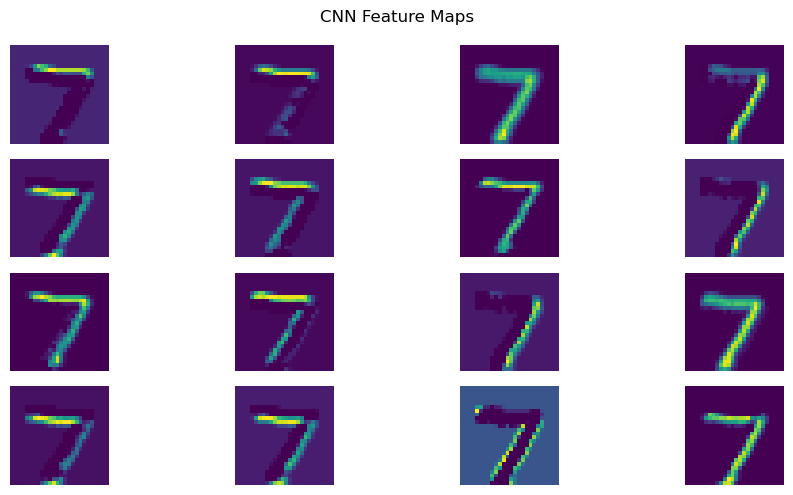

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step


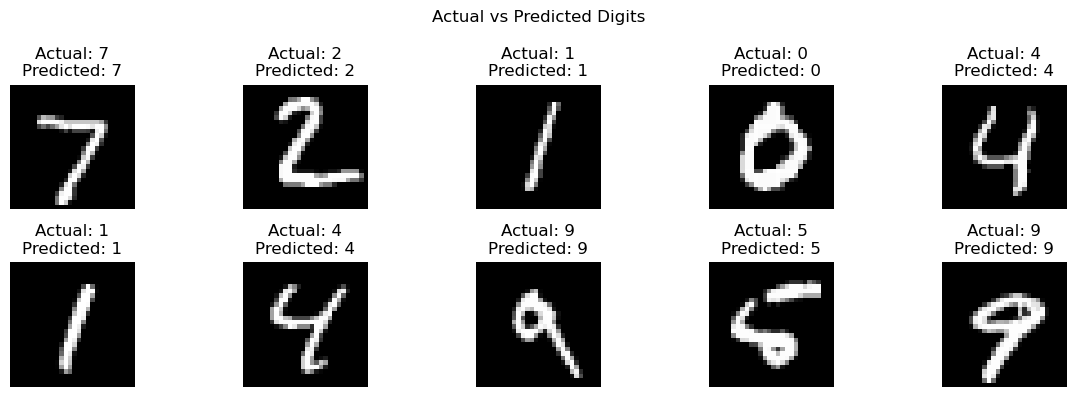

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

# 1. Load MNIST CSV Dataset
train_data = pd.read_csv(r"mnist_test.csv")
test_data = pd.read_csv(r"mnist_test.csv")

print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

# 2. Separate Features and Labels
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values
X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

# 3. Normalize and Reshape Images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# 4. Build CNN Model
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu", name="conv1"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu", name="conv2"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

# 5. Compile Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. Train CNN
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# 7. Evaluate Model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# 8. Visualize Feature Maps
# Create feature extraction model using the first convolution layer
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv1").output
)

# Get feature maps
feature_maps = feature_model.predict(X_test[:1], verbose=0)

# Display first 16 feature maps
plt.figure(figsize=(10, 5))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.axis("off")

plt.suptitle("CNN Feature Maps")
plt.tight_layout()
plt.show()

# 9. Display Actual and Predicted Digits
predictions = model.predict(X_test[:10])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(
        "Actual: " + str(y_test[i]) +
        "\nPredicted: " + str(predicted_labels[i])
    )
    plt.axis("off")

plt.suptitle("Actual vs Predicted Digits")
plt.tight_layout()
plt.show()